In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

sys.path.append("..")

from src.load import loadMatches
from src.split import splitMatches

# Pass model (xPass)
The model gives the chance that a pass reaches a teammate. We add features in three layers: where the pass starts and where it goes, then the context, then the 360 features.

## Loading the clean passes and the shared split

In [2]:
passes = pd.read_parquet("../data/clean/passes.parquet")

print("Passes:", len(passes))
print("Matches:", passes["match_id"].nunique())
print("Success rate:", round(passes["success"].mean(), 3))

Passes: 371845
Matches: 418
Success rate: 0.826


In [3]:
matches = loadMatches()
split = splitMatches(matches)
passes = passes.merge(split, on="match_id", how="left")

print("Train passes:", (passes["test"] == False).sum())
print("Test passes:", (passes["test"] == True).sum())
print(passes.groupby("fold")["match_id"].nunique())

Train passes: 217782
Test passes: 154063
fold
0    181
1     48
2     47
3     54
4     47
5     41
Name: match_id, dtype: int64


The split comes from src/split.py, so the pass model uses the same test rule and the same folds as the goal model.

## Layer 1: start spot and direction

In [4]:
GOAL_X = 120
GOAL_Y = 40


def addStartFeatures(passes):
    """Where the pass starts, which way it goes and how far."""
    passes["forward"] = np.cos(passes["pass_angle"])
    passes["sideways"] = np.abs(np.sin(passes["pass_angle"]))
    passes["length"] = passes["pass_length"]
    passes["startGoal"] = np.sqrt((GOAL_X - passes["x"]) ** 2 + (GOAL_Y - passes["y"]) ** 2)
    passes["endGoal"] = np.sqrt((GOAL_X - passes["endX"]) ** 2 + (GOAL_Y - passes["endY"]) ** 2)
    passes["gain"] = passes["startGoal"] - passes["endGoal"]
    return passes


passes = addStartFeatures(passes)

START = ["x", "y", "forward", "sideways", "length", "startGoal", "endGoal", "gain"]

print(passes[START].describe().round(2))

               x          y    forward   sideways     length  startGoal  \
count  371845.00  371845.00  371845.00  371845.00  371845.00  371845.00   
mean       59.05      39.77       0.18       0.66      19.49      66.39   
std        26.92      23.14       0.66       0.31      12.64      23.81   
min         0.10       0.10      -1.00       0.00       0.00       4.46   
25%        39.40      19.90      -0.36       0.40      10.83      48.02   
50%        58.60      39.70       0.30       0.75      16.31      64.90   
75%        78.80      59.60       0.81       0.95      24.49      83.87   
max       120.00      80.00       1.00       1.00     111.51     125.10   

         endGoal       gain  
count  371845.00  371845.00  
mean       61.35       5.04  
std        25.22      14.19  
min         0.00     -63.05  
25%        43.39      -3.84  
50%        60.62       3.45  
75%        79.29      10.99  
max       125.51     102.30  


The angle is turned into forward and sideways parts, because an angle of 3.1 and -3.1 are both backwards but look far apart as numbers.

## Layer 2: context (height, type, pressure)

In [5]:
SET_PIECES = ["Corner", "Free Kick", "Throw-in", "Goal Kick", "Kick Off"]


def addContextFeatures(passes):
    """Turn the height, type and body part into 0/1 columns."""
    passes["ground"] = (passes["pass_height"] == "Ground Pass").astype(int)
    passes["low"] = (passes["pass_height"] == "Low Pass").astype(int)
    passes["high"] = (passes["pass_height"] == "High Pass").astype(int)
    passes["setPiece"] = passes["pass_type"].isin(SET_PIECES).astype(int)
    passes["corner"] = (passes["pass_type"] == "Corner").astype(int)
    passes["throwIn"] = (passes["pass_type"] == "Throw-in").astype(int)
    passes["goalKick"] = (passes["pass_type"] == "Goal Kick").astype(int)
    passes["recovery"] = passes["pass_type"].isin(["Recovery", "Interception"]).astype(int)
    passes["header"] = (passes["pass_body_part"] == "Head").astype(int)
    passes["counter"] = (passes["play_pattern"] == "From Counter").astype(int)
    return passes


passes = addContextFeatures(passes)

CONTEXT = [
    "ground",
    "low",
    "high",
    "setPiece",
    "corner",
    "throwIn",
    "goalKick",
    "recovery",
    "header",
    "counter",
    "under_pressure",
    "counterpress",
    "pass_cross",
    "pass_switch",
    "pass_through_ball",
]

print(passes[CONTEXT].mean().round(3))

ground               0.743
low                  0.100
high                 0.157
setPiece             0.050
corner               0.006
throwIn              0.022
goalKick             0.005
recovery             0.088
header               0.033
counter              0.006
under_pressure       0.150
counterpress         0.004
pass_cross           0.021
pass_switch          0.022
pass_through_ball    0.005
dtype: float64


## Layer 3: features from the 360 frame
For each pass we look at the players in its frame: opponents close to the passer, opponents standing in the passing lane, opponents and teammates near where the pass ends, and open teammates ahead of the ball.

In [6]:
NEAR = 5
LANE = 2
OPEN = 5


def laneDistance(px, py, sx, sy, ex, ey):
    """Shortest distance from a player to the line between the start and end of the pass."""
    dx = ex - sx
    dy = ey - sy
    lengthSquared = dx * dx + dy * dy
    if lengthSquared == 0:
        return np.sqrt((px - sx) ** 2 + (py - sy) ** 2)
    t = ((px - sx) * dx + (py - sy) * dy) / lengthSquared
    t = np.clip(t, 0, 1)
    closestX = sx + t * dx
    closestY = sy + t * dy
    return np.sqrt((px - closestX) ** 2 + (py - closestY) ** 2)


def frameFeatures(frame, sx, sy, ex, ey):
    """Count the players around the pass for one frame."""
    mates = []
    opponents = []
    for player in frame:
        if player["actor"]:
            continue
        spot = player["location"]
        if player["teammate"]:
            mates.append(spot)
        else:
            opponents.append(spot)

    mates = np.array(mates).reshape(-1, 2)
    opponents = np.array(opponents).reshape(-1, 2)

    oppToStart = np.sqrt((opponents[:, 0] - sx) ** 2 + (opponents[:, 1] - sy) ** 2)
    oppToEnd = np.sqrt((opponents[:, 0] - ex) ** 2 + (opponents[:, 1] - ey) ** 2)
    mateToEnd = np.sqrt((mates[:, 0] - ex) ** 2 + (mates[:, 1] - ey) ** 2)
    oppInLane = laneDistance(opponents[:, 0], opponents[:, 1], sx, sy, ex, ey)

    openMates = 0
    for spot in mates:
        if spot[0] <= sx:
            continue
        gaps = np.sqrt((opponents[:, 0] - spot[0]) ** 2 + (opponents[:, 1] - spot[1]) ** 2)
        if len(gaps) == 0 or gaps.min() > OPEN:
            openMates += 1

    features = {}
    features["oppNearPasser"] = int((oppToStart < NEAR).sum())
    features["oppInLane"] = int((oppInLane < LANE).sum())
    features["oppNearEnd"] = int((oppToEnd < NEAR).sum())
    features["mateNearEnd"] = int((mateToEnd < NEAR).sum())
    features["closestOppEnd"] = float(oppToEnd.min()) if len(oppToEnd) > 0 else 50.0
    features["closestMateEnd"] = float(mateToEnd.min()) if len(mateToEnd) > 0 else 50.0
    features["openAhead"] = openMates
    features["visible"] = len(mates) + len(opponents)
    return features

In [7]:
first = passes.iloc[0]
print(frameFeatures(first["frame"], first["x"], first["y"], first["endX"], first["endY"]))

{'oppNearPasser': 0, 'oppInLane': 0, 'oppNearEnd': 0, 'mateNearEnd': 1, 'closestOppEnd': 10.919820116463994, 'closestMateEnd': 3.165808431370811, 'openAhead': 1, 'visible': 19}


In [8]:
def addFrameFeatures(passes):
    """Run frameFeatures on every pass."""
    rows = []
    for frame, sx, sy, ex, ey in zip(passes["frame"], passes["x"], passes["y"], passes["endX"], passes["endY"]):
        rows.append(frameFeatures(frame, sx, sy, ex, ey))
    table = pd.DataFrame(rows, index=passes.index)
    return pd.concat([passes, table], axis=1)


passes = addFrameFeatures(passes)

FRAME = [
    "oppNearPasser",
    "oppInLane",
    "oppNearEnd",
    "mateNearEnd",
    "closestOppEnd",
    "closestMateEnd",
    "openAhead",
    "visible",
]

print(passes[FRAME].describe().round(2))

       oppNearPasser  oppInLane  oppNearEnd  mateNearEnd  closestOppEnd  \
count      371845.00  371845.00   371845.00    371845.00      371845.00   
mean            0.77       0.49        0.23         0.50          12.36   
std             0.76       0.73        0.59         0.56           8.48   
min             0.00       0.00        0.00         0.00           0.02   
25%             0.00       0.00        0.00         0.00           6.29   
50%             1.00       0.00        0.00         0.00          10.61   
75%             1.00       1.00        0.00         1.00          16.44   
max             7.00       8.00       10.00         6.00          97.19   

       closestMateEnd  openAhead    visible  
count       371845.00  371845.00  371845.00  
mean             8.28       2.41      14.75  
std              8.68       1.72       3.45  
min              0.01       0.00       0.00  
25%              2.97       1.00      13.00  
50%              5.22       2.00      15.00  
75

A quick look: does the pass get harder with more opponents in the lane?

In [9]:
print(passes.groupby(passes["oppInLane"].clip(upper=3))["success"].agg(["mean", "count"]).round(3))

            mean   count
oppInLane               
0          0.928  229206
1          0.710  111234
2          0.519   25050
3          0.383    6355


In [10]:
passes = passes.drop(columns=["frame", "area"])

## Scoring functions
Every model reports AUC, Brier score and log loss on train, validation and test. Accuracy is not used, because always guessing "completed" already gets about 80%.

src/evaluate.py and src/logreg.py are not in the repo yet. These functions stand in until Darpan merges them, then they get swapped for the imports.

In [11]:
def score(labels, predictions):
    """AUC, Brier score and log loss for one set of predictions."""
    predictions = np.clip(predictions, 1e-6, 1 - 1e-6)
    result = {}
    result["auc"] = roc_auc_score(labels, predictions)
    result["brier"] = brier_score_loss(labels, predictions)
    result["logloss"] = log_loss(labels, predictions)
    return result


def sigmoid(z):
    """Squash any number into a probability between 0 and 1."""
    return 1 / (1 + np.exp(-z))


def fitLogreg(X, y, rate=0.1, steps=2000):
    """Logistic regression by gradient descent on log loss."""
    rows = X.shape[0]
    X = np.hstack([np.ones((rows, 1)), X])
    weights = np.zeros(X.shape[1])
    for step in range(steps):
        predictions = sigmoid(X @ weights)
        gradient = X.T @ (predictions - y) / rows
        weights = weights - rate * gradient
    return weights


def predictLogreg(weights, X):
    """Chance of success for each row."""
    rows = X.shape[0]
    X = np.hstack([np.ones((rows, 1)), X])
    return sigmoid(X @ weights)


def scaleFit(X):
    """Mean and spread from the training rows only."""
    mean = X.mean(axis=0)
    spread = X.std(axis=0)
    spread[spread == 0] = 1
    return mean, spread


def scaleApply(X, mean, spread):
    """Scale any rows with the training mean and spread."""
    return (X - mean) / spread

Checking the hand-written logistic regression against sklearn on a sample of training passes.

In [12]:
SAMPLE = 50000

train = passes[passes["test"] == False]
sample = train.sample(SAMPLE, random_state=2026)
X = sample[START].to_numpy(dtype=float)
y = sample["success"].to_numpy()
mean, spread = scaleFit(X)
X = scaleApply(X, mean, spread)

weights = fitLogreg(X, y)
ours = predictLogreg(weights, X)

library = LogisticRegression(max_iter=1000)
library.fit(X, y)
theirs = library.predict_proba(X)[:, 1]

print("Our AUC:", round(roc_auc_score(y, ours), 4))
print("sklearn AUC:", round(roc_auc_score(y, theirs), 4))

Our AUC: 0.8233
sklearn AUC: 0.8239


## Cross-validation by match
Each model is trained 5 times, each time leaving one fold of matches out. The left-out predictions give the validation score. Then the model is trained on all training matches and scored once on the test matches.

In [13]:
def runLogreg(passes, features):
    """Out-of-fold, train and test predictions for the hand-written logistic regression."""
    train = passes[passes["test"] == False]
    test = passes[passes["test"] == True]
    outOfFold = pd.Series(np.nan, index=train.index)
    trainScores = []

    for fold in sorted(train["fold"].unique()):
        fitRows = train[train["fold"] != fold]
        holdRows = train[train["fold"] == fold]
        X = fitRows[features].to_numpy(dtype=float)
        mean, spread = scaleFit(X)
        weights = fitLogreg(scaleApply(X, mean, spread), fitRows["success"].to_numpy())
        fitPredictions = predictLogreg(weights, scaleApply(X, mean, spread))
        trainScores.append(score(fitRows["success"], fitPredictions))
        holdX = scaleApply(holdRows[features].to_numpy(dtype=float), mean, spread)
        outOfFold[holdRows.index] = predictLogreg(weights, holdX)

    X = train[features].to_numpy(dtype=float)
    mean, spread = scaleFit(X)
    weights = fitLogreg(scaleApply(X, mean, spread), train["success"].to_numpy())
    testPredictions = predictLogreg(weights, scaleApply(test[features].to_numpy(dtype=float), mean, spread))
    return outOfFold, pd.Series(testPredictions, index=test.index), pd.DataFrame(trainScores).mean()


def runXgb(passes, features, settings):
    """Out-of-fold, train and test predictions for XGBoost."""
    train = passes[passes["test"] == False]
    test = passes[passes["test"] == True]
    outOfFold = pd.Series(np.nan, index=train.index)
    trainScores = []

    for fold in sorted(train["fold"].unique()):
        fitRows = train[train["fold"] != fold]
        holdRows = train[train["fold"] == fold]
        model = XGBClassifier(**settings)
        model.fit(fitRows[features], fitRows["success"])
        trainScores.append(score(fitRows["success"], model.predict_proba(fitRows[features])[:, 1]))
        outOfFold[holdRows.index] = model.predict_proba(holdRows[features])[:, 1]

    model = XGBClassifier(**settings)
    model.fit(train[features], train["success"])
    testPredictions = model.predict_proba(test[features])[:, 1]
    return outOfFold, pd.Series(testPredictions, index=test.index), pd.DataFrame(trainScores).mean(), model


def tableRow(name, passes, outOfFold, testPredictions, trainScores):
    """One row of the train/validation/test table."""
    train = passes[passes["test"] == False]
    test = passes[passes["test"] == True]
    validation = score(train["success"], outOfFold)
    testing = score(test["success"], testPredictions)
    row = {}
    row["model"] = name
    row["trainAuc"] = trainScores["auc"]
    row["validationAuc"] = validation["auc"]
    row["testAuc"] = testing["auc"]
    row["testBrier"] = testing["brier"]
    row["testLogloss"] = testing["logloss"]
    return row

## Baseline: always guess the average

In [14]:
results = []

train = passes[passes["test"] == False]
test = passes[passes["test"] == True]
average = train["success"].mean()
baseline = score(test["success"], np.full(len(test), average))

print("Always guessing", round(average, 3), "->", baseline)

Always guessing 0.842 -> {'auc': 0.5, 'brier': 0.1597480257473793, 'logloss': 0.5017014000071394}


## Logistic regression: layer 1, then all layers

In [15]:
logStartOof, logStartTest, logStartTrain = runLogreg(passes, START)
results.append(tableRow("Logistic regression, start and direction", passes, logStartOof, logStartTest, logStartTrain))

ALL = START + CONTEXT + FRAME

logAllOof, logAllTest, logAllTrain = runLogreg(passes, ALL)
results.append(tableRow("Logistic regression, all features", passes, logAllOof, logAllTest, logAllTrain))

print(pd.DataFrame(results).round(3))

                                      model  trainAuc  validationAuc  testAuc  \
0  Logistic regression, start and direction     0.823          0.823    0.813   
1         Logistic regression, all features     0.925          0.925    0.917   

   testBrier  testLogloss  
0      0.122        0.390  
1      0.090        0.285  


## XGBoost: tuning on the validation folds only
A small grid. The test passes are not used to pick the setting.

In [16]:
BASE = {
    "n_estimators": 300,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "n_jobs": 2,
    "random_state": 2026,
}

grid = [
    {"max_depth": 3, "min_child_weight": 1},
    {"max_depth": 5, "min_child_weight": 1},
    {"max_depth": 5, "min_child_weight": 20},
    {"max_depth": 7, "min_child_weight": 20},
]

tuning = []
for option in grid:
    settings = {**BASE, **option}
    outOfFold, testPredictions, trainScores, model = runXgb(passes, ALL, settings)
    validation = score(train["success"], outOfFold)
    tuning.append({**option, "trainAuc": trainScores["auc"], "validationAuc": validation["auc"]})
    print(option, "validation AUC:", round(validation["auc"], 4))

tuning = pd.DataFrame(tuning)
best = tuning.sort_values("validationAuc", ascending=False).iloc[0]
bestSettings = {**BASE, "max_depth": int(best["max_depth"]), "min_child_weight": int(best["min_child_weight"])}

print(tuning.round(4))
print("Best setting:", bestSettings)

{'max_depth': 3, 'min_child_weight': 1} validation AUC: 0.9397


{'max_depth': 5, 'min_child_weight': 1} validation AUC: 0.9419


{'max_depth': 5, 'min_child_weight': 20} validation AUC: 0.9417


{'max_depth': 7, 'min_child_weight': 20} validation AUC: 0.942
   max_depth  min_child_weight  trainAuc  validationAuc
0          3                 1    0.9431         0.9397
1          5                 1    0.9538         0.9419
2          5                20    0.9506         0.9417
3          7                20    0.9594         0.9420
Best setting: {'n_estimators': 300, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'n_jobs': 2, 'random_state': 2026, 'max_depth': 7, 'min_child_weight': 20}


## XGBoost layer by layer with the best setting
This shows how much each layer of features adds.

In [17]:
layers = {
    "XGBoost, start and direction": START,
    "XGBoost, + context": START + CONTEXT,
    "XGBoost, + 360 features": ALL,
}

for name, features in layers.items():
    outOfFold, testPredictions, trainScores, model = runXgb(passes, features, bestSettings)
    results.append(tableRow(name, passes, outOfFold, testPredictions, trainScores))
    print(name, "done")

xgbOof = outOfFold
xgbTest = testPredictions
finalModel = model

XGBoost, start and direction done


XGBoost, + context done


XGBoost, + 360 features done


## Train / validation / test table

In [18]:
table = pd.DataFrame(results)
table = table.round(3)

print(table.to_string(index=False))

Path("../outputs").mkdir(exist_ok=True)
table.to_csv("../outputs/pass_results.csv", index=False)

                                   model  trainAuc  validationAuc  testAuc  testBrier  testLogloss
Logistic regression, start and direction     0.823          0.823    0.813      0.122        0.390
       Logistic regression, all features     0.925          0.925    0.917      0.090        0.285
            XGBoost, start and direction     0.907          0.883    0.878      0.102        0.328
                      XGBoost, + context     0.932          0.913    0.910      0.090        0.289
                 XGBoost, + 360 features     0.959          0.942    0.937      0.078        0.247


## Calibration
If the model says 70%, about 70% of those passes should be completed.

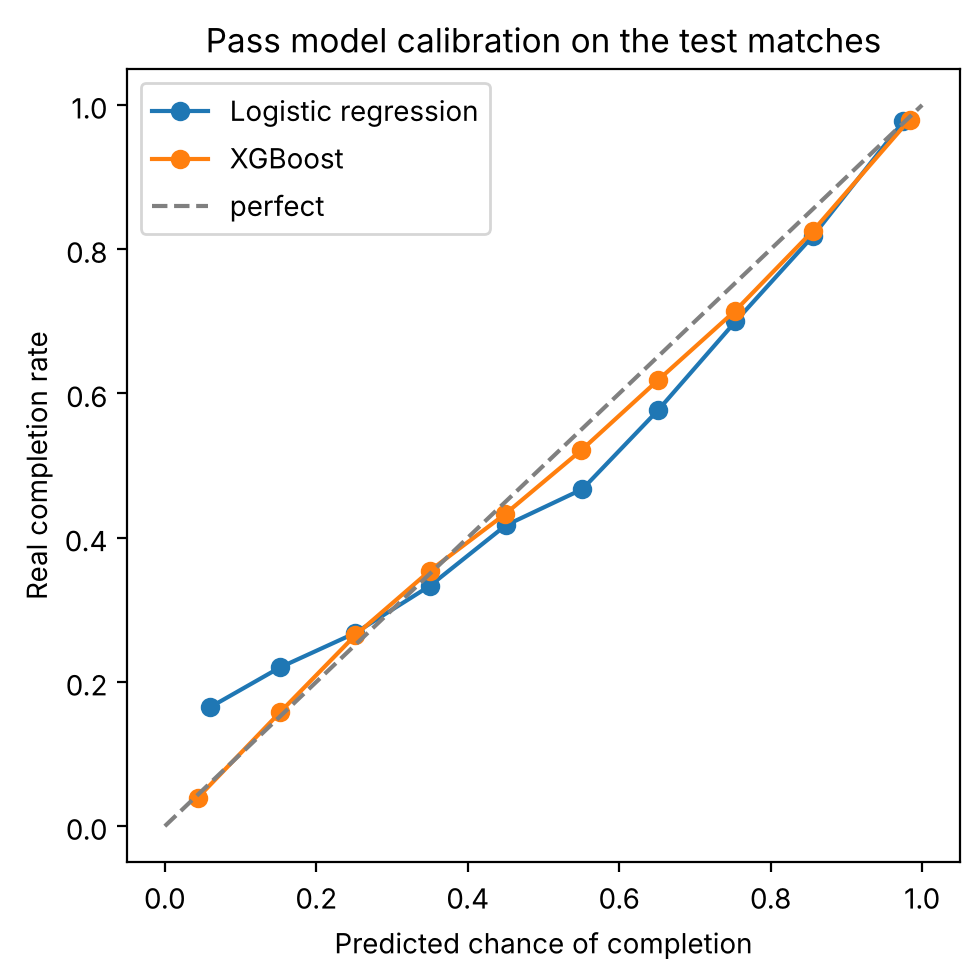

In [19]:
BINS = 10

fig, ax = plt.subplots(figsize=(5, 5))
for name, predictions in [("Logistic regression", logAllTest), ("XGBoost", xgbTest)]:
    real, predicted = calibration_curve(test["success"], predictions, n_bins=BINS)
    ax.plot(predicted, real, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect")
ax.set_xlabel("Predicted chance of completion")
ax.set_ylabel("Real completion rate")
ax.set_title("Pass model calibration on the test matches")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/pass_calibration.png", dpi=150)
plt.show()

## Which features the final model leans on

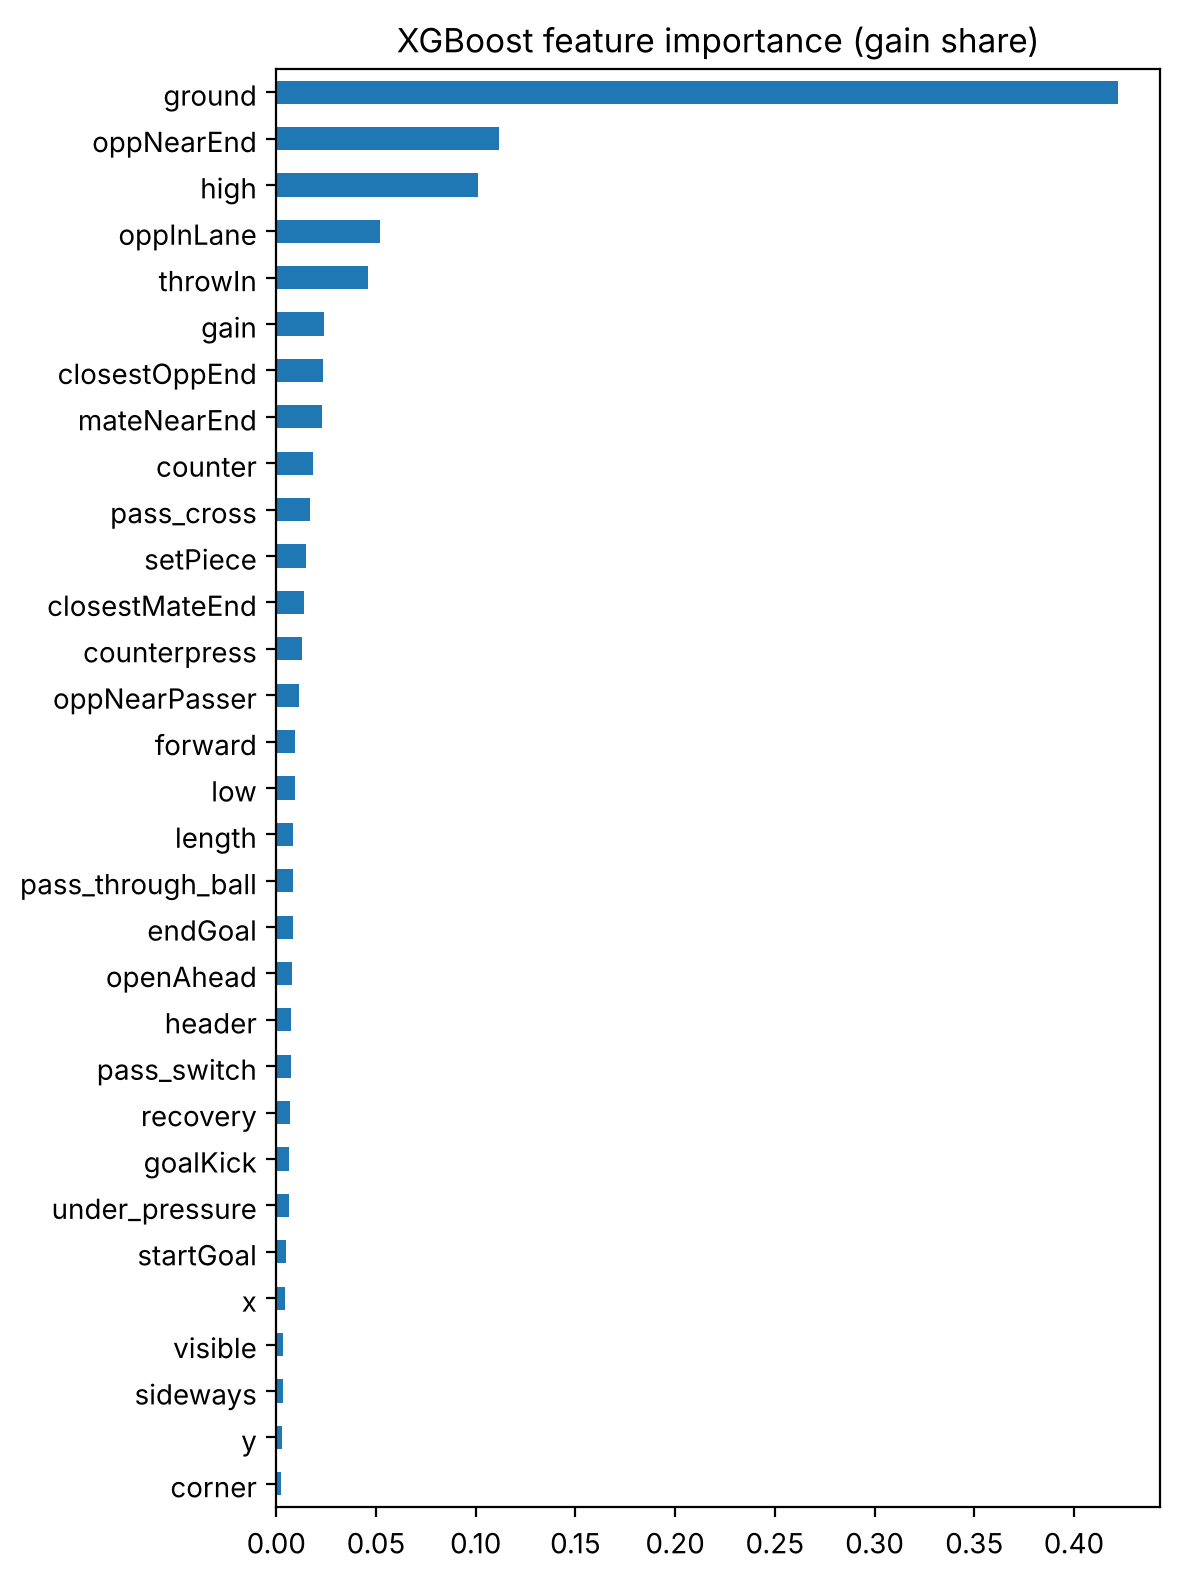

In [20]:
importance = pd.Series(finalModel.feature_importances_, index=ALL).sort_values()

fig, ax = plt.subplots(figsize=(6, 8))
importance.plot.barh(ax=ax)
ax.set_title("XGBoost feature importance (gain share)")
plt.tight_layout()
plt.savefig("../outputs/pass_importance.png", dpi=150)
plt.show()

## Saving xpass_oof.parquet
Training passes get their out-of-fold prediction, test passes get the prediction from the model trained on all training matches. So no pass is ever scored by a model that saw it.

In [21]:
xpass = passes[["id", "match_id", "team", "player", "player_id", "x", "y", "endX", "endY", "success", "fold", "test"]].copy()
xpass["xpassLogreg"] = pd.concat([logAllOof, logAllTest])
xpass["xpass"] = pd.concat([xgbOof, xgbTest])

print("Missing predictions:", xpass[["xpassLogreg", "xpass"]].isna().sum().to_dict())
print(xpass.head())

xpass.to_parquet("../outputs/xpass_oof.parquet", index=False)
print("Saved outputs/xpass_oof.parquet:", len(xpass))

Missing predictions: {'xpassLogreg': 0, 'xpass': 0}
                                     id  match_id              team  \
0  6c546c19-5f61-4236-a1ad-0b6f5cded692   3895292      Union Berlin   
1  a7fdbea2-aabe-498d-ac0d-ebd6e3edabca   3895292      Union Berlin   
2  f3647dd4-0731-472b-b2e8-31b01e772fc7   3895292      Union Berlin   
3  ba8350af-91ff-4a29-a646-d88829863907   3895292      Union Berlin   
4  7b049f8b-d62e-412b-9d79-471b00f9e8b4   3895292  Bayer Leverkusen   

             player  player_id     x     y  endX  endY  success  fold  test  \
0  Brenden Aaronson    24243.0  61.0  40.1  58.5  38.9        1     0  True   
1    András Schäfer    42822.0  58.8  38.6  35.9  50.9        1     0  True   
2    Danilho Doekhi    18789.0  37.9  52.2  86.1   6.0        1     0  True   
3      Robin Gosens     6985.0  84.3   6.2  94.2  16.7        0     0  True   
4   Odilon Kossonou    27133.0  25.9  63.4  36.1  63.4        0     0  True   

   xpassLogreg     xpass  
0     0.993355  0.9

Saved outputs/xpass_oof.parquet: 371845
